In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv('train.csv')

print("=== SHAPE DATASET ===")
print(df.shape)

print("\n=== INFORMASI DATASET ===")
df.info()

print("\n=== LIMA BARIS PERTAMA ===")
display(df.head())

=== SHAPE DATASET ===
(1460, 81)

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   objec

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
missing_percent = df.isnull().mean() * 100

cols_to_drop = missing_percent[missing_percent > 50].index
df_cleaned = df.drop(columns=cols_to_drop)
print(f"Kolom yang dihapus (>50% missing): {list(cols_to_drop)}")

num_cols = df_cleaned.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df_cleaned.select_dtypes(include=['object']).columns

for col in num_cols:
    df_cleaned[col].fillna(df_cleaned[col].median(), inplace=True)

for col in cat_cols:
    df_cleaned[col].fillna(df_cleaned[col].mode()[0], inplace=True)

print(f"Sisa missing values: {df_cleaned.isnull().sum().sum()}")

Kolom yang dihapus (>50% missing): ['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature']
Sisa missing values: 0


C:\Users\eeksa\AppData\Local\Temp\ipykernel_26048\522082156.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_cleaned[col].fillna(df_cleaned[col].median(), inplace=True)
C:\Users\eeksa\AppData\Local\Temp\ipykernel_26048\522082156.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a 

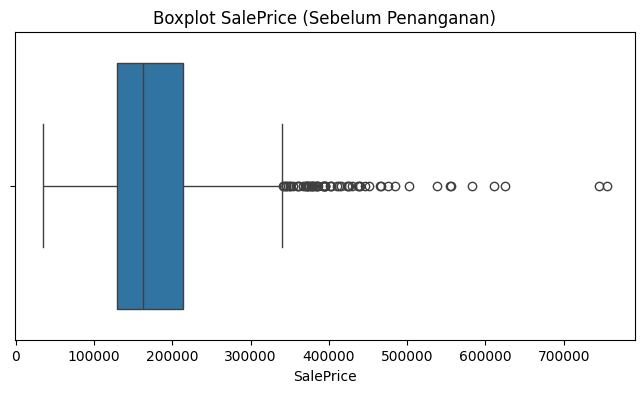

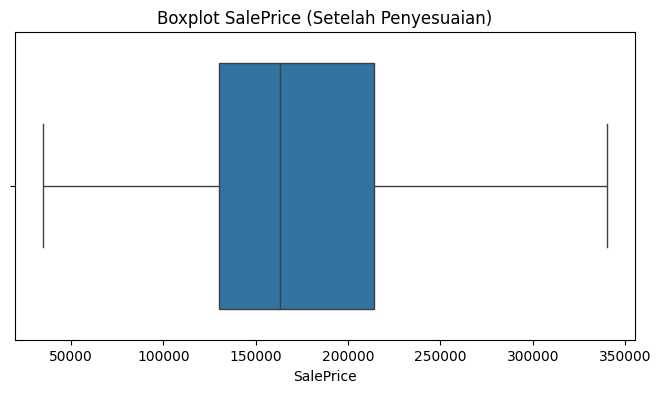

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_cleaned['SalePrice'])
plt.title('Boxplot SalePrice (Sebelum Penanganan)')
plt.show()

for col in num_cols:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_cleaned[col] = np.where(df_cleaned[col] < lower_bound, lower_bound, df_cleaned[col])
    df_cleaned[col] = np.where(df_cleaned[col] > upper_bound, upper_bound, df_cleaned[col])

plt.figure(figsize=(8, 4))
sns.boxplot(x=df_cleaned['SalePrice'])
plt.title('Boxplot SalePrice (Setelah Penyesuaian)')
plt.show()

In [ ]:
scaler = StandardScaler()
df_scaled = df_cleaned.copy()

features_to_scale = [col for col in num_cols if col not in ['Id', 'SalePrice']]
df_scaled[features_to_scale] = scaler.fit_transform(df_scaled[features_to_scale])

df_transformed = pd.get_dummies(df_scaled, columns=cat_cols, drop_first=True)

print(f"Dimensi dataset setelah One-Hot Encoding: {df_transformed.shape}")

Dimensi dataset setelah One-Hot Encoding: (1460, 235)


In [ ]:
corr_matrix = df_transformed[features_to_scale].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.8)]
df_reduced_corr = df_transformed.drop(columns=to_drop)

print(f"Atribut yang dihapus karena korelasi tinggi: {to_drop}")

X = df_reduced_corr.drop(columns=['Id', 'SalePrice'])
y = df_reduced_corr['SalePrice']

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X)

print(f"Jumlah komponen PCA yang dipertahankan: {pca.n_components_}")

pca_columns = [f'PC{i+1}' for i in range(X_pca.shape[1])]
df_final = pd.DataFrame(X_pca, columns=pca_columns)
df_final['SalePrice'] = y.values
df_final['Id'] = df_reduced_corr['Id'].values

display(df_final.head())

Atribut yang dihapus karena korelasi tinggi: ['1stFlrSF', 'TotRmsAbvGrd', 'GarageArea']
Jumlah komponen PCA yang dipertahankan: 65


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC58,PC59,PC60,PC61,PC62,PC63,PC64,PC65,SalePrice,Id
0,2.430233,0.260611,-1.599412,-1.798784,0.883164,-1.762907,-0.506578,-1.442465,-0.626521,-0.344102,...,0.003680,-0.180683,0.012607,0.110172,-0.101877,-0.060429,-0.048376,0.000431,208500.0,1.0
1,-0.141502,-1.442216,1.481287,-0.009761,1.099381,0.873410,0.044816,1.867514,0.640850,-0.338278,...,-0.024527,0.308696,0.163229,-0.327527,0.653952,-0.109114,0.035747,-0.198866,181500.0,2.0
2,2.998348,0.560550,-0.649765,-1.345754,0.010514,-0.378814,-1.145722,-0.299037,-0.003102,0.277661,...,-0.069618,-0.009284,-0.151615,0.061839,-0.186517,-0.027925,-0.134473,0.050951,223500.0,3.0
3,-0.575073,0.977255,0.342536,-0.616439,-0.559435,0.197803,0.171172,-0.647609,-0.046881,-2.272164,...,-0.176827,0.285280,-0.066096,-0.199672,-0.093689,-0.633909,0.378188,-0.014386,140000.0,4.0
4,5.023555,1.006597,1.139949,-1.323301,-0.459013,0.090567,-1.170222,0.246616,-0.311150,1.603101,...,-0.092032,0.351682,-0.087335,-0.257962,0.155911,0.163905,-0.048951,-0.110069,250000.0,5.0


In [6]:
nrp = "5054251041"
nama = "Maulana Rhys Pradana"
filename = f"{nrp}_{nama}_Tugas_Praproses_Data.csv"

df_final.to_csv(filename, index=False)
print(f"Dataset akhir berhasil disimpan sebagai: {filename}")

Dataset akhir berhasil disimpan sebagai: 5054251041_Maulana Rhys Pradana_Tugas_Praproses_Data.csv
